In [1]:
#당뇨병 데이터를 가지고 당뇨병을 분류하는 최적화된 딥러닝 모델을 구하고 마지막에 정확도를 출력하시오 
#11월12일 오전 9시까지
#<처리조건>
#정확도는 accuracy_score()를 사용한다
#학습데이터와 테스트 데이터는 8:2비율로한다
#sigmold(),numerical_derivative()를 사용한다
#Logicgate클래스를 수정하여 모델을 설계한다
#은닉층은 1개이상사용할것

In [2]:
#정확도를 최대한 향상 
#결측치제거 / 이상치제거 /스케일링 (스탠다드스케일러,민맥스스케일러) / 로그변환

In [3]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score

df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
print(df.shape)

(768, 9)


In [5]:
print(df.isnull().sum()) #컬럼별 결측치개수
print("=====================")
print(df.duplicated().sum()) #중복행갯수

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
0


In [6]:
print(df.describe())
#Pregnancies 임신 횟수
#Glucose 혈장 포도당 농도
#BloodPressure 최저혈압
#SkinThickness 피부주름두께 
#Insulin 인슐린
#DiabetesPedigreeFunction 당뇨병가족력
#Outcome 정답

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [7]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_cnt = (df[zero_cols] == 0).sum()
print(zero_cnt)

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [8]:
print(df.loc[df['Insulin'] != 0, 'Insulin'].min())
#인슐린값중에 df가 0이아닌 최소값


14


In [9]:
import numpy as np
from sklearn.model_selection import train_test_split

#  0을 NaN으로 바꾸기 (0이 나올 수 없는 컬럼만)
#  -> 0을 넣은채로 중앙값을하면 값이이상해질수있음. 그래서 NAN으로 바꾸고 값을구하려고함
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[zero_cols] = df[zero_cols].replace(0, np.nan)
print(df.isnull().sum())          # 결측 개수 확인


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
#분포가 대칭이면 평균, 치우쳤거나 이상치가 있으면 중앙값
#대칭에 가깝고 이상치 없음 (왜도 절댓값 0.5 이하 정도)	평균. 중앙값을 써도 거의 같음
#치우쳤거나 극단값이 있음 (왜도 절댓값 1 이상 정도)	중앙값


skew = df[zero_cols].skew().sort_values(ascending=False)
# 판다스에서 왜도 계산
df.drop(columns=['Outcome']).skew().sort_values(ascending=False)    

Insulin                     2.166464
DiabetesPedigreeFunction    1.919911
Age                         1.129597
Pregnancies                 0.901674
SkinThickness               0.690619
BMI                         0.593970
Glucose                     0.530989
BloodPressure               0.134153
dtype: float64

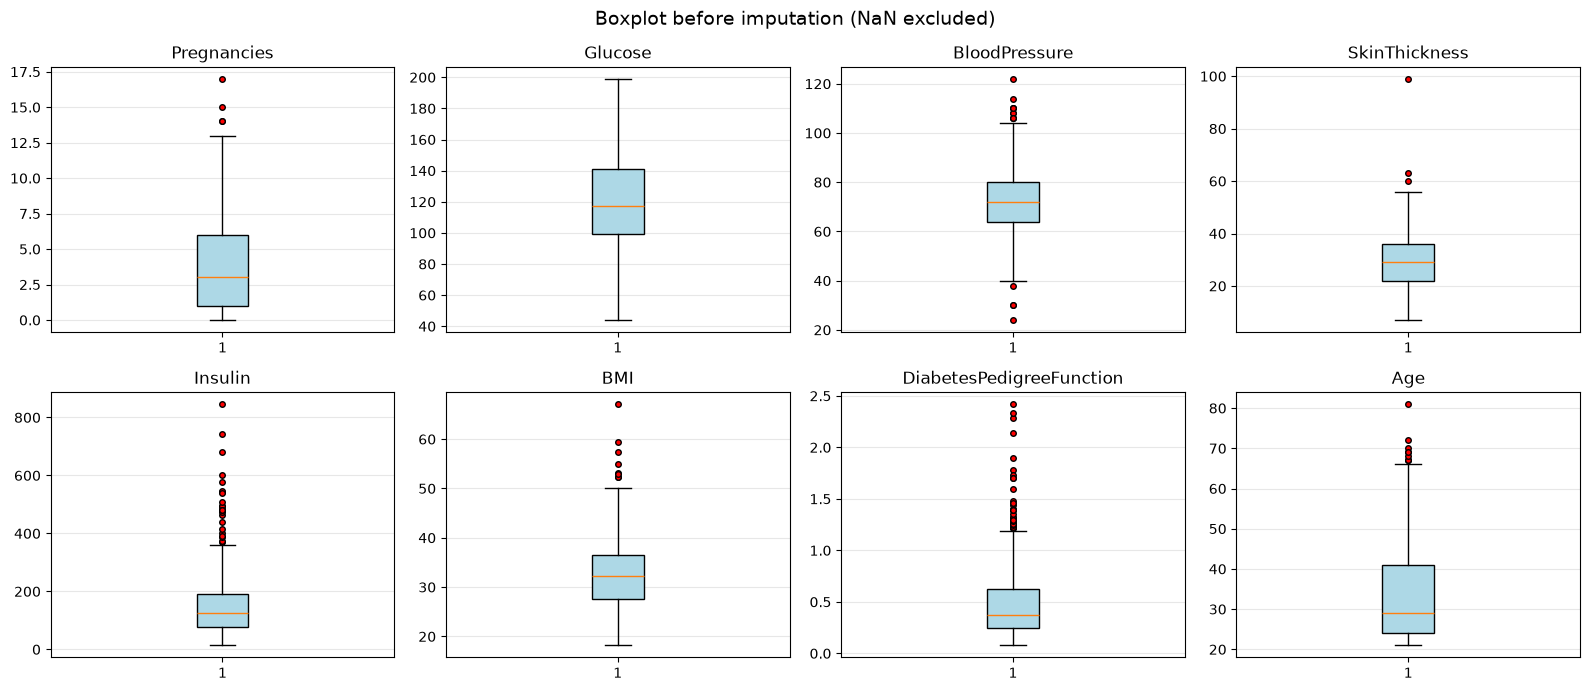

Pregnancies                  4
Glucose                      0
BloodPressure               14
SkinThickness                3
Insulin                     24
BMI                          8
DiabetesPedigreeFunction    29
Age                          9
dtype: int64


In [11]:
import matplotlib.pyplot as plt

cols = df.drop(columns=['Outcome']).columns

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, col in zip(axes.flatten(), cols):
    ax.boxplot(df[col].dropna(), orientation='vertical', patch_artist=True,
               boxprops=dict(facecolor='lightblue'),
               flierprops=dict(marker='o', markerfacecolor='red', markersize=4))
    ax.set_title(col)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Boxplot before imputation (NaN excluded)', fontsize=14)
plt.tight_layout()
plt.show()

# 컬럼별 이상치 개수 (IQR 기준, NaN 제외)
X_all = df.drop(columns=['Outcome'])
Q1 = X_all.quantile(0.25)
Q3 = X_all.quantile(0.75)
IQR = Q3 - Q1
outlier_cnt = ((X_all < Q1 - 1.5 * IQR) | (X_all > Q3 + 1.5 * IQR)).sum()
print(outlier_cnt)

#혈압 최하 이상치는 3건이라 그냥 넘어감 

In [12]:

#  train / test 나누기
#-> 결측값을 채우기전에 나누어 데이터누수 방지
X = df.drop('Outcome', axis=1)
#8개 특성 컬럼만 남은 DataFrame
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 3. train의 중앙값으로 둘 다 채우기
median = X_train[zero_cols].median()
print(median)  # 채워질 값 확인

X_train[zero_cols] = X_train[zero_cols].fillna(median)
X_test[zero_cols] = X_test[zero_cols].fillna(median)

# 4. 확인
print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())   # 둘 다 0이면 성공

Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.4
dtype: float64
0 0


In [16]:
#  로그 변환: 왜도 1 초과 컬럼만
skew = df.drop(columns=['Outcome']).skew().sort_values(ascending=False)
log_cols = skew[skew > 1].index.tolist()
print('로그 변환 컬럼:', log_cols)

X_train[log_cols] = np.log1p(X_train[log_cols])
X_test[log_cols] = np.log1p(X_test[log_cols])

# 확인: 변환 전후 왜도 비교 
before = df[log_cols].skew()
after = np.log1p(df[log_cols]).skew()
print(pd.DataFrame({'변환 전': before, '변환 후': after}).round(3))

로그 변환 컬럼: ['Insulin', 'DiabetesPedigreeFunction', 'Age']
                           변환 전   변환 후
Insulin                   2.166 -0.088
DiabetesPedigreeFunction  1.920  1.118
Age                       1.130  0.615


In [17]:
from sklearn.preprocessing import StandardScaler

# 6. 스케일링 (StandardScaler: 평균 0, 표준편차 1)
#   -> train에만 fit, test는 transform만 해서 데이터 누수 방지
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 확인: train은 평균 0, 표준편차 1에 가까우면 성공
print(X_train_scaled.mean(axis=0).round(2))
print(X_train_scaled.std(axis=0).round(2))

# 7. 정답을 (n, 1) 모양의 numpy 배열로 변환
y_train_np = y_train.values.reshape(-1, 1)
y_test_np = y_test.values.reshape(-1, 1)
print(X_train_scaled.shape, y_train_np.shape, X_test_scaled.shape, y_test_np.shape)
# (614, 8) (614, 1) (154, 8) (154, 1)

[-0. -0.  0. -0.  0.  0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1.]
(614, 8) (614, 1) (154, 8) (154, 1)
